# FIFA World Cup Intelligence
### Exploratory Data Analysis · Machine Learning · GenAI

An end-to-end football analytics portfolio project combining evidence-based analysis of team, player, and match data with synthetic-scenario model evaluation and a natural-language analytics assistant.

**Workflow:** data quality → exploratory analysis → findings → synthetic-scenario ML → GenAI question answering.

> **Scope and integrity:** EDA findings describe only the supplied CSV files. Verify source provenance and coverage before presenting them as authoritative tournament facts. The ML labels are synthetic; model scores do **not** establish real-world match prediction accuracy.

**Run instructions**
1. Keep `teams.csv`, `players.csv`, and `matches.csv` beside this notebook or in a `data/` folder.
2. Run cells from top to bottom.
3. The Gemini assistant is optional and never calls the API automatically.

## 1. Install dependencies

In [8]:
%pip install -q -U google-genai pandas numpy matplotlib seaborn plotly scipy scikit-learn joblib


Note: you may need to restart the kernel to use updated packages.


  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.


## 2. Imports and reproducibility

In [10]:
from pathlib import Path
import os
import warnings
import json
import re
from getpass import getpass

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go
import plotly.io as pio
from plotly.subplots import make_subplots
from scipy import stats
from google import genai
from IPython.display import display
import plotly.io as pio

In [11]:
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, precision_recall_fscore_support,
    classification_report, ConfusionMatrixDisplay, confusion_matrix,
    silhouette_score
)
from sklearn.dummy import DummyClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier, ExtraTreesClassifier, GradientBoostingClassifier,
    HistGradientBoostingClassifier
)
from sklearn.cluster import KMeans

# Consistent notebook styling
warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid", context="notebook")
pio.templates.default = "plotly_white"
pio.renderers.default = "notebook_connected"
PLOTLY_KW = dict(template="plotly_white")

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
pd.set_option("display.max_columns", 100)
print("Imports ready. Gemini SDK:", genai.__name__)


Imports ready. Gemini SDK: google.genai


## 3. Load datasets and inspect the data inventory

The loader checks the notebook folder, common `data/` folders, and the Windows project folder. Dataset previews use selected columns to keep wide tables readable.

In [5]:
teams = pd.read_csv(r"E:\Fifa_DA\Fifa\teams.csv")
players = pd.read_csv(r"E:\Fifa_DA\Fifa\players.csv")
matches = pd.read_csv(r"E:\Fifa_DA\Fifa\matches.csv")
synthetic_matches = pd.read_csv(r"E:\Fifa_DA\Fifa\synthetic_matches.csv")
DATASETS = {"Teams": teams, "Players": players, "Matches": matches, "Synthetic_Matches": synthetic_matches}

dataset_names = [
    ("teams", teams, "Teams Dataset"),
    ("players", players, "Players Dataset"),
    ("matches", matches, "Match Statistics Dataset"),
    ("synthetic_matches", synthetic_matches, "Synthetic Match Scenarios Dataset"),
]

for name, frame, title in dataset_names:
    if frame is not None:
        print(f"\n{'=' * 60}", "\n")
        print(title,"\n")
        print(f"Dimensions: {frame.shape[0]:,} rows × {frame.shape[1]:,} columns", "\n")
        display(frame.head())



Teams Dataset 

Dimensions: 48 rows × 136 columns 



,team,team_country,players_used,avg_age,possession,games,games_starts,minutes,minutes_90s,goals,...,gk_wins_against,gk_ties_against,gk_losses_against,gk_clean_sheets_against,gk_clean_sheets_pct_against,gk_pens_att_against,gk_pens_allowed_against,gk_pens_saved_against,gk_pens_missed_against,gk_pens_save_pct_against
0,Algeria,Algeria,22,27.3,61.0,4,44,360,4.0,5,...,2,1,1,2,50.0,0,0,0,0,NaN
1,Argentina,Argentina,24,29.6,57.6,8,88,810,9.0,18,...,1,0,7,1,12.5,3,1,1,1,50.0
2,Australia,Australia,23,25.3,41.0,4,44,390,4.3,2,...,2,1,1,2,50.0,0,0,0,0,NaN
3,Austria,Austria,20,28.8,45.0,4,44,360,4.0,5,...,2,1,1,2,50.0,1,1,0,0,0.0
4,Belgium,Belgium,23,29.2,51.2,6,66,570,6.3,13,...,1,2,3,1,16.7,1,1,0,0,0.0




Players Dataset 

Dimensions: 1,248 rows × 72 columns 



,player,team,team_country,position,age,birth_year,club,games,games_starts,minutes,...,gk_wins,gk_ties,gk_losses,gk_clean_sheets,gk_clean_sheets_pct,gk_pens_att,gk_pens_allowed,gk_pens_saved,gk_pens_missed,gk_pens_save_pct
0,Achref Abada,Algeria,Algeria,DF,26,1999,NaN,0,0,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Adil Boulbina,Algeria,Algeria,FW,23,2003,NaN,2,0,19.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Amine Gouiri,Algeria,Algeria,FW,26,2000,Marseille,4,3,251.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,Anis Hadj Moussa,Algeria,Algeria,MF,24,2002,Feyenoord,3,1,98.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,Aïssa Mandi,Algeria,Algeria,DF,34,1991,Lille,4,4,360.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN




Match Statistics Dataset 

Dimensions: 104 rows × 42 columns 



,round,gameweek,dayofweek,date,start_time,home_team,away_team,score,home_score,away_score,...,away_fouls,home_corners,away_corners,home_crosses,away_crosses,home_interceptions,away_interceptions,home_offsides,away_offsides,notes
0,Group stage,1.0,Thu,2026-06-11,13:00,Mexico,South Africa,2–0,2.0,0.0,...,11,3,1,12,8,8,7,1.0,1.0,NaN
1,Group stage,1.0,Thu,2026-06-11,20:00,Korea Republic,Czechia,2–1,2.0,1.0,...,16,4,5,12,15,11,7,2.0,2.0,NaN
2,Group stage,1.0,Fri,2026-06-12,15:00,Canada,Bosnia–Herz,1–1,1.0,1.0,...,20,9,4,24,10,4,10,1.0,0.0,NaN
3,Group stage,1.0,Fri,2026-06-12,18:00,United States,Paraguay,4–1,4.0,1.0,...,17,3,1,17,5,11,9,2.0,1.0,NaN
4,Group stage,1.0,Sat,2026-06-13,12:00,Qatar,Switzerland,1–1,1.0,1.0,...,11,3,10,8,35,10,7,0.0,1.0,NaN




Synthetic Match Scenarios Dataset 

Dimensions: 20,000 rows × 22 columns 



,scenario_id,home_team,away_team,home_attack_index,away_attack_index,home_defence_index,away_defence_index,home_recent_form,away_recent_form,home_rest_days,...,home_possession_pct,away_possession_pct,home_shot_index,away_shot_index,strength_margin,scenario_tier,simulated_home_goals,simulated_away_goals,simulated_match_result,data_origin
0,1,Spain,South Africa,-1.2008,-1.2350,2.1270,1.5959,-0.6172,-0.7151,3,...,38.35,61.65,4.53,2.14,-0.4635,Balanced,0,1,Away win,synthetic_simulation
1,2,Canada,Türkiye,-1.6291,-0.0168,-0.4634,-1.7911,-0.1969,0.3311,8,...,34.75,65.25,11.51,11.45,-2.9851,Away-dominant,0,0,Draw,synthetic_simulation
2,3,Argentina,Côte d'Ivoire,0.5616,0.3463,-1.6112,-1.2661,-0.3636,0.0948,7,...,52.40,47.60,17.03,15.26,0.9093,Home-dominant,2,5,Away win,synthetic_simulation
3,4,New Zealand,Senegal,0.9235,0.4015,-0.3007,-0.7952,-0.4564,0.4201,3,...,71.62,28.38,12.35,10.09,-0.9351,Away-dominant,3,0,Home win,synthetic_simulation
4,5,England,Sweden,2.0550,-2.0592,0.9091,-0.4220,-0.7082,0.3699,3,...,74.47,25.53,17.39,3.75,1.4298,Home-dominant,2,1,Home win,synthetic_simulation


## 4. Data quality audit

Inspect missingness, duplicates, data types, and distinct values before interpreting patterns. Some missing values may be structural—for example, goalkeeper-only fields for outfield players.

In [6]:
def data_quality_report(df):
    return pd.DataFrame({
        "dtype": df.dtypes.astype(str),
        "missing_count": df.isna().sum(),
        "missing_pct": (df.isna().mean() * 100).round(2),
        "unique_values": df.nunique(dropna=True),
    }).sort_values(["missing_pct", "missing_count"], ascending=False)

for name, frame in DATASETS.items():
    if isinstance(frame, pd.DataFrame):
        print(f"\n{name}: {frame.duplicated().sum():,} duplicate rows")
        display(data_quality_report(frame).head(20))


Teams: 0 duplicate rows


,dtype,missing_count,missing_pct,unique_values
pens_won,float64,48,100.00,0
pens_conceded,float64,48,100.00,0
pens_won_against,float64,48,100.00,0
pens_conceded_against,float64,48,100.00,0
gk_pens_save_pct,float64,33,68.75,4
gk_pens_save_pct_against,float64,33,68.75,3
team,str,0,0.00,48
team_country,str,0,0.00,48
players_used,int64,0,0.00,9
avg_age,float64,0,0.00,34



Players: 0 duplicate rows


,dtype,missing_count,missing_pct,unique_values
pens_won,float64,1248,100.00,0
pens_conceded,float64,1248,100.00,0
gk_pens_save_pct,float64,1233,98.80,4
gk_clean_sheets_pct,float64,1190,95.35,10
gk_save_pct,float64,1189,95.27,43
gk_games,float64,1186,95.03,8
gk_games_starts,float64,1186,95.03,9
gk_minutes,float64,1186,95.03,24
gk_goals_against,float64,1186,95.03,11
gk_goals_against_per90,float64,1186,95.03,34



Matches: 0 duplicate rows


,dtype,missing_count,missing_pct,unique_values
notes,str,95,91.35,5
gameweek,float64,32,30.77,3
home_offsides,float64,5,4.81,8
away_offsides,float64,5,4.81,7
home_score,float64,4,3.85,8
away_score,float64,4,3.85,7
round,str,0,0.00,7
dayofweek,str,0,0.00,7
date,str,0,0.00,34
start_time,str,0,0.00,14



Synthetic_Matches: 0 duplicate rows


,dtype,missing_count,missing_pct,unique_values
scenario_id,int64,0,0.0,20000
home_team,str,0,0.0,48
away_team,str,0,0.0,48
home_attack_index,float64,0,0.0,15251
away_attack_index,float64,0,0.0,15334
home_defence_index,float64,0,0.0,15297
away_defence_index,float64,0,0.0,15330
home_recent_form,float64,0,0.0,12795
away_recent_form,float64,0,0.0,12845
home_rest_days,int64,0,0.0,7


## 5. Match EDA: outcomes, scoring, and match flow

Explore match outcomes, scoreline distribution, trends over time, and relationships between shots, possession, and goal difference. These are descriptive associations, not proof of causation.

Matches with usable scores: 100


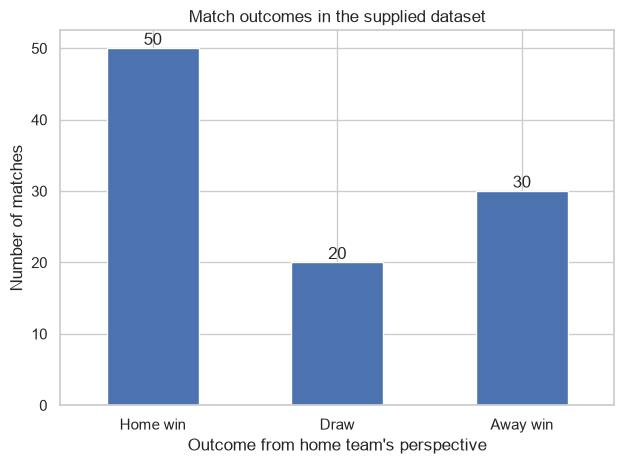

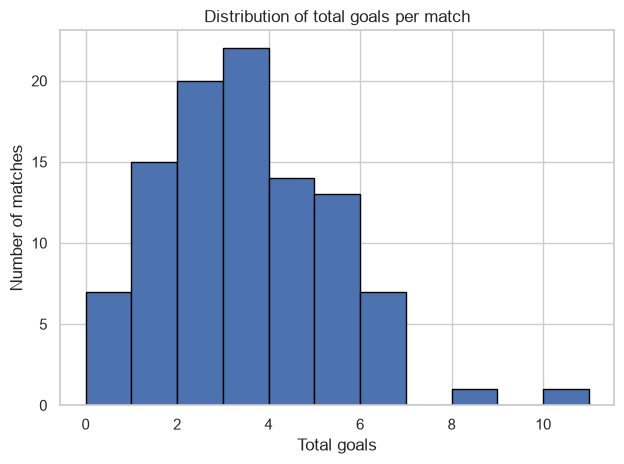

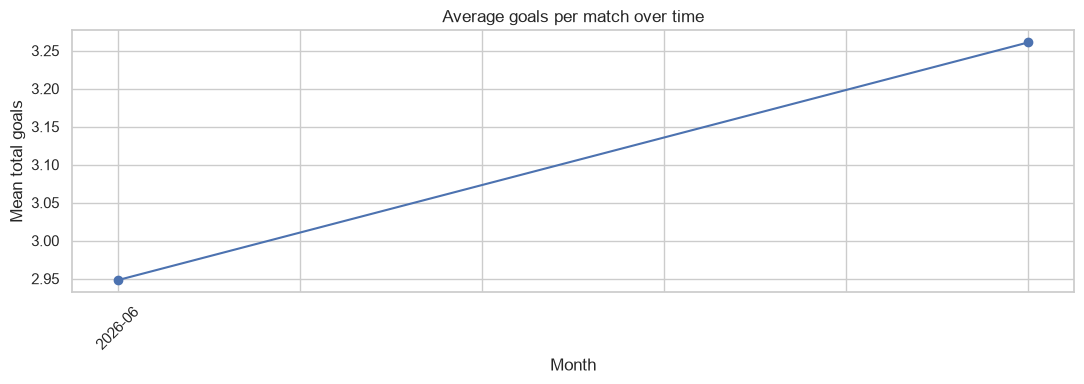

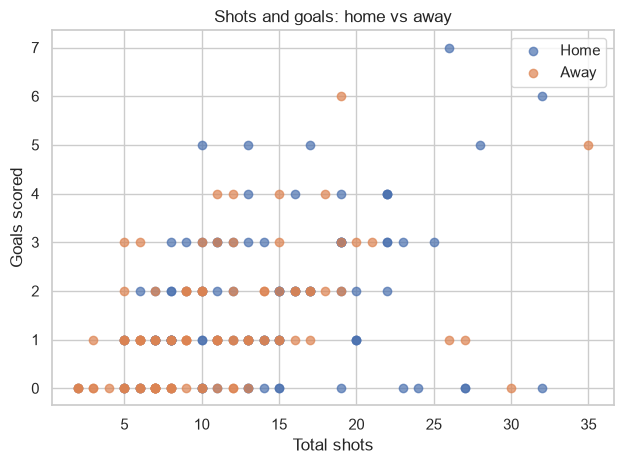

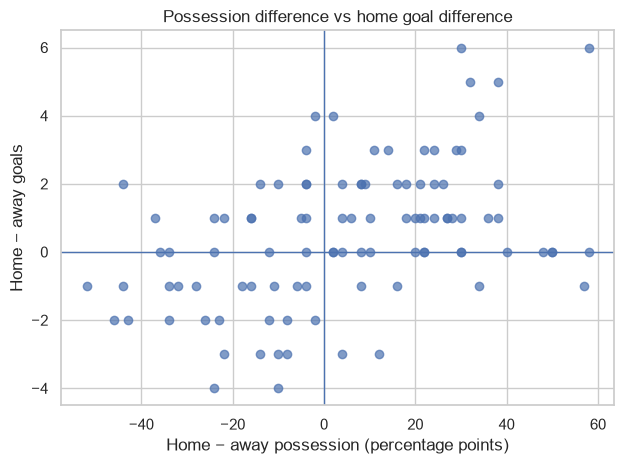

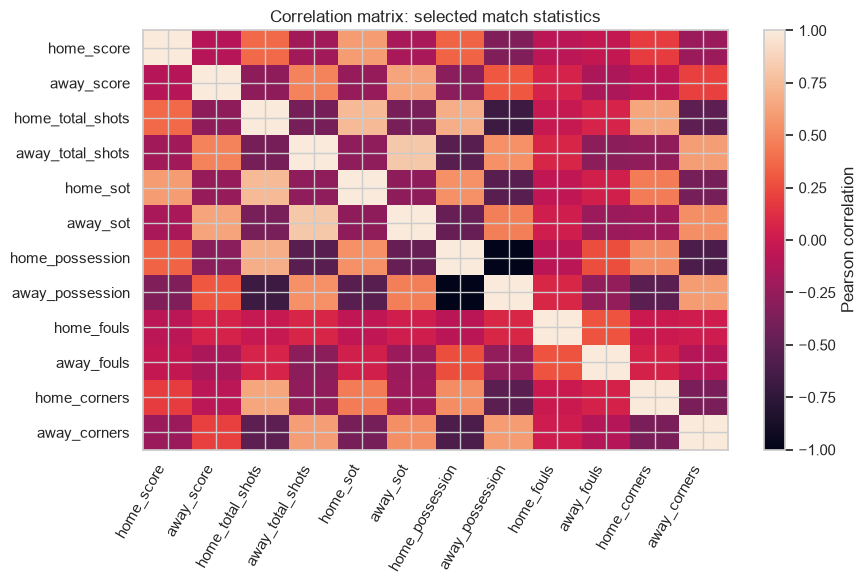

,date,round,home_team,away_team,home_score,away_score,total_goals,outcome
0,2026-06-11,Group stage,Mexico,South Africa,2.0,0.0,2.0,Home win
1,2026-06-11,Group stage,Korea Republic,Czechia,2.0,1.0,3.0,Home win
2,2026-06-12,Group stage,Canada,Bosnia–Herz,1.0,1.0,2.0,Draw
3,2026-06-12,Group stage,United States,Paraguay,4.0,1.0,5.0,Home win
4,2026-06-13,Group stage,Qatar,Switzerland,1.0,1.0,2.0,Draw
5,2026-06-13,Group stage,Brazil,Morocco,1.0,1.0,2.0,Draw
6,2026-06-13,Group stage,Australia,Türkiye,2.0,0.0,2.0,Home win
7,2026-06-13,Group stage,Haiti,Scotland,0.0,1.0,1.0,Away win
8,2026-06-14,Group stage,Germany,Curaçao,7.0,1.0,8.0,Home win
9,2026-06-14,Group stage,Netherlands,Japan,2.0,2.0,4.0,Draw


In [14]:
if matches is not None and {"home_score", "away_score"}.issubset(matches.columns):
    match_eda = matches.copy()
    match_eda["home_score"] = pd.to_numeric(match_eda["home_score"], errors="coerce")
    match_eda["away_score"] = pd.to_numeric(match_eda["away_score"], errors="coerce")
    match_eda = match_eda.dropna(subset=["home_score", "away_score"]).copy()
    match_eda["total_goals"] = match_eda["home_score"] + match_eda["away_score"]
    match_eda["home_goal_difference"] = match_eda["home_score"] - match_eda["away_score"]
    match_eda["outcome"] = np.select([match_eda["home_goal_difference"] > 0, match_eda["home_goal_difference"] < 0], ["Home win", "Away win"], default="Draw")
    print(f"Matches with usable scores: {len(match_eda):,}")

    counts = match_eda["outcome"].value_counts().reindex(["Home win", "Draw", "Away win"]).fillna(0)
    fig, ax = plt.subplots()
    counts.plot(kind="bar", ax=ax)
    ax.set_title("Match outcomes in the supplied dataset")
    ax.set_xlabel("Outcome from home team's perspective")
    ax.set_ylabel("Number of matches")
    ax.tick_params(axis="x", rotation=0)
    ax.bar_label(ax.containers[0], fmt="%.0f")
    plt.tight_layout(); plt.show()

    fig, ax = plt.subplots()
    match_eda["total_goals"].plot(kind="hist", bins=range(0, int(match_eda["total_goals"].max()) + 2), edgecolor="black", ax=ax)
    ax.set_title("Distribution of total goals per match")
    ax.set_xlabel("Total goals"); ax.set_ylabel("Number of matches")
    plt.tight_layout(); plt.show()

    match_eda["date"] = pd.to_datetime(
    match_eda["date"],
    errors="coerce"
    )
    
    if "date" in match_eda.columns:
        dated = match_eda.dropna(subset=["date"]).copy()
        if not dated.empty:
            dated["month"] = dated["date"].dt.to_period("M").astype(str)
            monthly = dated.groupby("month")["total_goals"].mean()
            fig, ax = plt.subplots(figsize=(11, 4)); monthly.plot(marker="o", ax=ax)
            ax.set_title("Average goals per match over time"); ax.set_xlabel("Month"); ax.set_ylabel("Mean total goals")
            ax.tick_params(axis="x", rotation=45); plt.tight_layout(); plt.show()

    for col in ["home_total_shots", "away_total_shots", "home_possession", "away_possession"]:
        if col in match_eda.columns: match_eda[col] = pd.to_numeric(match_eda[col], errors="coerce")
    if {"home_total_shots", "home_score"}.issubset(match_eda.columns):
        fig, ax = plt.subplots()
        ax.scatter(match_eda["home_total_shots"], match_eda["home_score"], alpha=.7, label="Home")
        if {"away_total_shots", "away_score"}.issubset(match_eda.columns): ax.scatter(match_eda["away_total_shots"], match_eda["away_score"], alpha=.7, label="Away")
        ax.set_title("Shots and goals: home vs away"); ax.set_xlabel("Total shots"); ax.set_ylabel("Goals scored"); ax.legend()
        plt.tight_layout(); plt.show()
    if {"home_possession", "away_possession"}.issubset(match_eda.columns):
        match_eda["possession_difference"] = match_eda["home_possession"] - match_eda["away_possession"]
        fig, ax = plt.subplots(); ax.scatter(match_eda["possession_difference"], match_eda["home_goal_difference"], alpha=.7)
        ax.axhline(0, linewidth=1); ax.axvline(0, linewidth=1)
        ax.set_title("Possession difference vs home goal difference"); ax.set_xlabel("Home − away possession (percentage points)"); ax.set_ylabel("Home − away goals")
        plt.tight_layout(); plt.show()

    corr_cols = [c for c in ["home_score", "away_score", "home_total_shots", "away_total_shots", "home_sot", "away_sot", "home_possession", "away_possession", "home_fouls", "away_fouls", "home_corners", "away_corners"] if c in match_eda.columns]
    corr = match_eda[corr_cols].corr(numeric_only=True)
    if corr.shape[1] >= 2:
        fig, ax = plt.subplots(figsize=(9, 6)); im = ax.imshow(corr, aspect="auto", vmin=-1, vmax=1)
        ax.set_xticks(range(len(corr.columns)), corr.columns, rotation=60, ha="right"); ax.set_yticks(range(len(corr.index)), corr.index)
        ax.set_title("Correlation matrix: selected match statistics"); fig.colorbar(im, ax=ax, label="Pearson correlation")
        plt.tight_layout(); plt.show()
    display(match_eda[[c for c in ["date", "round", "home_team", "away_team", "home_score", "away_score", "total_goals", "outcome"] if c in match_eda.columns]].head(10))
else:
    print("Match EDA skipped: home_score and away_score are required.")

## 6. Team performance analysis

Compare scoring, defensive record, possession, and goal difference using the actual team-table fields.

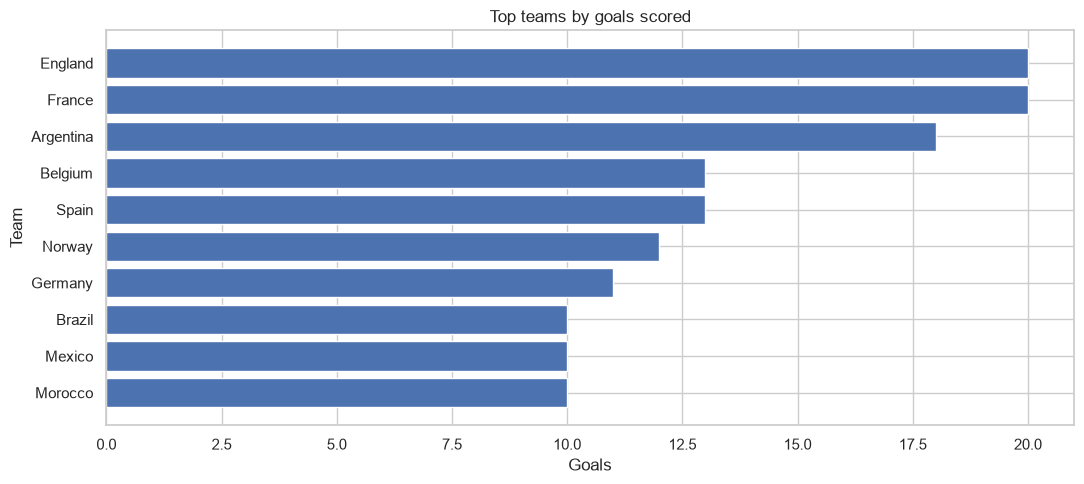

Top teams by goal difference


,team,goals,goals_against,goal_difference,possession,points_per_game
40,Spain,13,1,12,64.1,2.75
1,Argentina,18,8,10,57.6,2.63
18,France,20,10,10,55.9,2.25
17,England,20,12,8,54.1,2.38
27,Mexico,10,3,7,52.2,2.40
4,Belgium,13,7,6,51.2,1.83
6,Brazil,10,4,6,53.0,2.00
19,Germany,11,5,6,65.0,1.75
28,Morocco,10,5,5,59.0,1.83
29,Netherlands,10,5,5,53.3,2.00


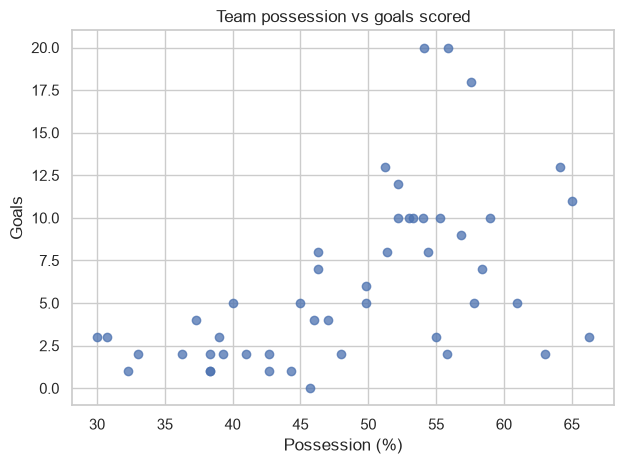

Teams with the fewest goals conceded


,team,goals_against,goals,goal_difference,possession
9,Colombia,1,5,4,57.8
40,Spain,1,13,12,64.1
2,Australia,2,2,0,41.0
20,Ghana,3,2,-1,36.3
22,IR Iran,3,3,0,39.0
26,Korea Republic,3,2,-1,63.0
27,Mexico,3,10,7,52.2
34,Portugal,3,7,4,58.4
6,Brazil,4,10,6,53.0
7,Cabo Verde,4,4,0,37.3


In [15]:
if teams is not None and "team" in teams.columns:
    team_eda = teams.copy()
    for col in ["goals", "goals_against", "possession", "points_per_game", "plus_minus"]:
        if col in team_eda.columns: team_eda[col] = pd.to_numeric(team_eda[col], errors="coerce")
    if {"goals", "goals_against"}.issubset(team_eda.columns):
        team_eda["goal_difference"] = team_eda["goals"] - team_eda["goals_against"]
        top = team_eda.nlargest(10, "goals")
        fig, ax = plt.subplots(figsize=(11, 5)); ax.barh(top["team"].astype(str)[::-1], top["goals"][::-1])
        ax.set_title("Top teams by goals scored"); ax.set_xlabel("Goals"); ax.set_ylabel("Team")
        plt.tight_layout(); plt.show()
        print("Top teams by goal difference")
        display(team_eda.nlargest(10, "goal_difference")[[c for c in ["team", "goals", "goals_against", "goal_difference", "possession", "points_per_game"] if c in team_eda.columns]])
    if {"possession", "goals"}.issubset(team_eda.columns):
        fig, ax = plt.subplots(); ax.scatter(team_eda["possession"], team_eda["goals"], alpha=.75)
        ax.set_title("Team possession vs goals scored"); ax.set_xlabel("Possession (%)"); ax.set_ylabel("Goals")
        plt.tight_layout(); plt.show()
    if "goals_against" in team_eda.columns:
        print("Teams with the fewest goals conceded")
        display(team_eda.nsmallest(10, "goals_against")[[c for c in ["team", "goals_against", "goals", "goal_difference", "possession"] if c in team_eda.columns]])
else:
    print("Team analysis skipped: teams.csv with a 'team' column is required.")

## 7. Player performance analysis

Explore goals, assists, age, position, playing time, and per-90 rates. Per-90 comparisons help account for different minutes played, but rates can be unstable for players with very little playing time.

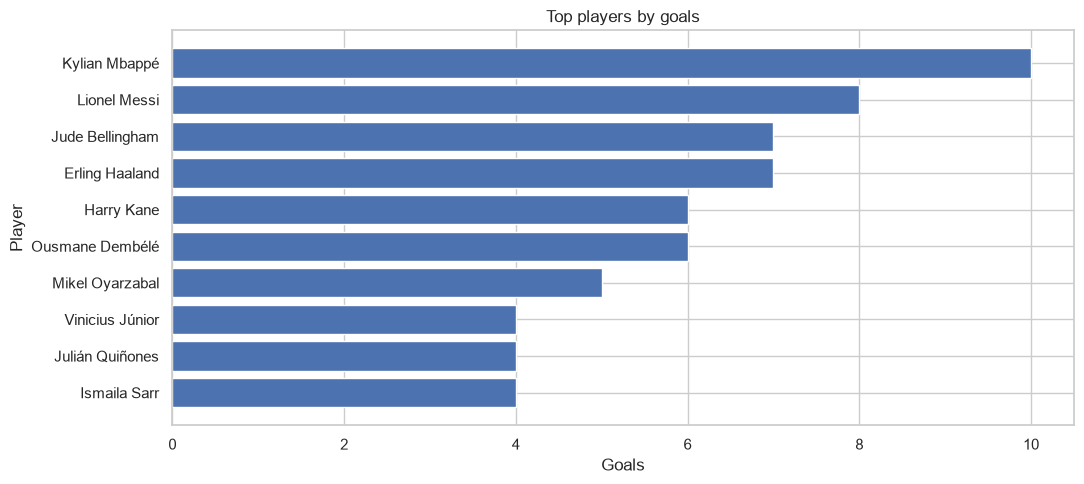

,player,team,position,games,minutes,goals,assists,goals_per90
477,Kylian Mbappé,France,FW,8,695.0,10.0,4.0,1.29
41,Lionel Messi,Argentina,FW,8,740.0,8.0,4.0,0.97
458,Jude Bellingham,England,MF,8,614.0,7.0,1.0,1.03
811,Erling Haaland,Norway,FW,5,465.0,7.0,0.0,1.35
451,Harry Kane,England,FW,7,652.0,6.0,1.0,0.83
488,Ousmane Dembélé,France,MF,8,592.0,6.0,2.0,0.91
1055,Mikel Oyarzabal,Spain,FW,8,601.0,5.0,1.0,0.75
179,Vinicius Júnior,Brazil,FW,5,440.0,4.0,1.0,0.82
717,Julián Quiñones,Mexico,"FW,MF",5,410.0,4.0,1.0,0.88
1000,Ismaila Sarr,Senegal,"MF,FW",4,364.0,4.0,1.0,0.99


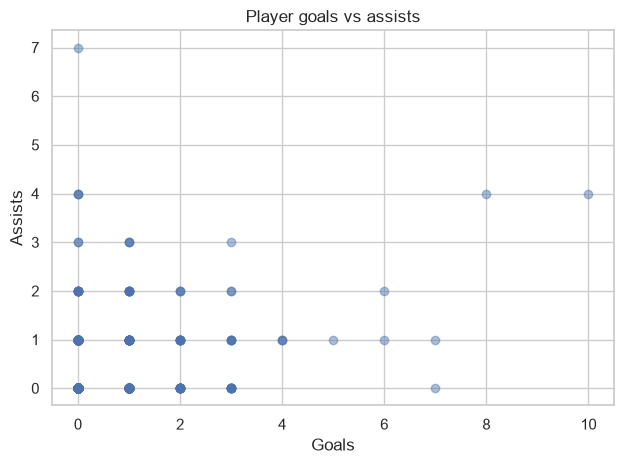

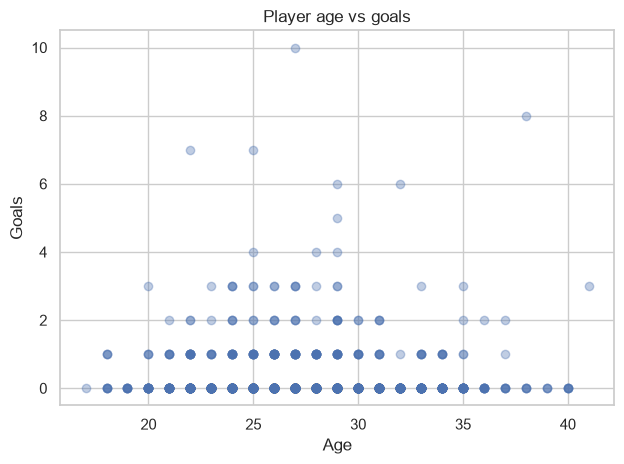

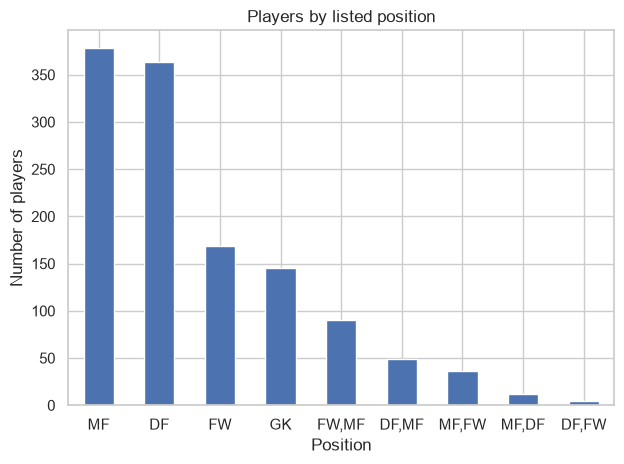

Top goal rate per 90 minutes (minimum 450 minutes)


,player,team,position,minutes,goals,goals_per90
811,Erling Haaland,Norway,FW,465.0,7.0,1.35
477,Kylian Mbappé,France,FW,695.0,10.0,1.29
458,Jude Bellingham,England,MF,614.0,7.0,1.03
41,Lionel Messi,Argentina,FW,740.0,8.0,0.97
488,Ousmane Dembélé,France,MF,592.0,6.0,0.91
451,Harry Kane,England,FW,652.0,6.0,0.83
1055,Mikel Oyarzabal,Spain,FW,601.0,5.0,0.75
128,Youri Tielemans,Belgium,MF,474.0,2.0,0.38
117,Leandro Trossard,Belgium,"MF,FW",506.0,2.0,0.36
1094,Breel Embolo,Switzerland,FW,501.0,2.0,0.36


In [16]:
if players is not None and "player" in players.columns:
    player_eda = players.copy()
    for col in ["age", "minutes", "goals", "assists", "games", "goals_per90"]:
        if col in player_eda.columns: player_eda[col] = pd.to_numeric(player_eda[col], errors="coerce")
    if "goals" in player_eda.columns:
        top = player_eda.dropna(subset=["goals"]).nlargest(10, "goals")
        fig, ax = plt.subplots(figsize=(11, 5)); ax.barh(top["player"].astype(str)[::-1], top["goals"][::-1])
        ax.set_title("Top players by goals"); ax.set_xlabel("Goals"); ax.set_ylabel("Player")
        plt.tight_layout(); plt.show()
        display(top[[c for c in ["player", "team", "position", "games", "minutes", "goals", "assists", "goals_per90"] if c in top.columns]])
    if {"goals", "assists"}.issubset(player_eda.columns):
        fig, ax = plt.subplots(); ax.scatter(player_eda["goals"], player_eda["assists"], alpha=.45)
        ax.set_title("Player goals vs assists"); ax.set_xlabel("Goals"); ax.set_ylabel("Assists")
        plt.tight_layout(); plt.show()
    if {"age", "goals"}.issubset(player_eda.columns):
        valid = player_eda.dropna(subset=["age", "goals"])
        fig, ax = plt.subplots(); ax.scatter(valid["age"], valid["goals"], alpha=.35)
        ax.set_title("Player age vs goals"); ax.set_xlabel("Age"); ax.set_ylabel("Goals")
        plt.tight_layout(); plt.show()
    if "position" in player_eda.columns:
        counts = player_eda["position"].fillna("Unknown").value_counts()
        fig, ax = plt.subplots(); counts.plot(kind="bar", ax=ax)
        ax.set_title("Players by listed position"); ax.set_xlabel("Position"); ax.set_ylabel("Number of players")
        ax.tick_params(axis="x", rotation=0); plt.tight_layout(); plt.show()
    if "goals_per90" not in player_eda.columns and {"goals", "minutes"}.issubset(player_eda.columns):
        player_eda["goals_per90"] = np.where(player_eda["minutes"] > 0, player_eda["goals"] / player_eda["minutes"] * 90, np.nan)
    if {"goals_per90", "minutes"}.issubset(player_eda.columns):
        eligible = player_eda[(player_eda["minutes"] >= 450) & player_eda["goals_per90"].notna()]
        print("Top goal rate per 90 minutes (minimum 450 minutes)")
        display(eligible.nlargest(10, "goals_per90")[[c for c in ["player", "team", "position", "minutes", "goals", "goals_per90"] if c in eligible.columns]])
else:
    print("Player analysis skipped: players.csv with a 'player' column is required.")

## 8. Evidence-based findings snapshot

This compact summary is computed from the actual columns available in your files. Use it to guide your interpretation; verify the data source and coverage before making broad claims.

In [17]:
eda_summary = {}
if matches is not None and {"home_score", "away_score"}.issubset(matches.columns):
    temp = matches.copy()
    temp["home_score"] = pd.to_numeric(temp["home_score"], errors="coerce")
    temp["away_score"] = pd.to_numeric(temp["away_score"], errors="coerce")
    temp = temp.dropna(subset=["home_score", "away_score"])
    if not temp.empty:
        diff = temp["home_score"] - temp["away_score"]
        eda_summary["matches_with_scores"] = int(len(temp))
        eda_summary["mean_total_goals"] = round(float((temp["home_score"] + temp["away_score"]).mean()), 2)
        eda_summary["home_win_share_pct"] = round(float((diff > 0).mean() * 100), 1)
        eda_summary["draw_share_pct"] = round(float((diff == 0).mean() * 100), 1)
        eda_summary["away_win_share_pct"] = round(float((diff < 0).mean() * 100), 1)
if teams is not None and {"team", "goals"}.issubset(teams.columns):
    temp = teams.copy(); temp["goals"] = pd.to_numeric(temp["goals"], errors="coerce"); temp = temp.dropna(subset=["goals"])
    if not temp.empty:
        row = temp.loc[temp["goals"].idxmax()]; eda_summary["top_team_by_goals_in_supplied_table"] = str(row["team"]); eda_summary["top_team_goals"] = int(row["goals"])
if players is not None and {"player", "goals"}.issubset(players.columns):
    temp = players.copy(); temp["goals"] = pd.to_numeric(temp["goals"], errors="coerce"); temp = temp.dropna(subset=["goals"])
    if not temp.empty:
        row = temp.loc[temp["goals"].idxmax()]; eda_summary["top_player_by_goals_in_supplied_table"] = str(row["player"]); eda_summary["top_player_goals"] = int(row["goals"])
display(pd.DataFrame([{"Metric": k.replace("_", " ").title(), "Value": v} for k, v in eda_summary.items()]))
print("Interpret the metrics in context; the summary does not establish causation or validate the source data.")

,Metric,Value
0,Matches With Scores,100
1,Mean Total Goals,3.02
2,Home Win Share Pct,50.0
3,Draw Share Pct,20.0
4,Away Win Share Pct,30.0
5,Top Team By Goals In Supplied Table,England
6,Top Team Goals,20
7,Top Player By Goals In Supplied Table,Kylian Mbappé
8,Top Player Goals,10


Interpret the metrics in context; the summary does not establish causation or validate the source data.


## 9. Generate a synthetic match-scenario dataset

In [18]:
# Synthetic features describe hypothetical pre-match conditions.
# The label is intentionally generated from a documented deterministic rule.
# This makes the task learnable, but the score is NOT real-world football accuracy.
N_SYNTHETIC = 20_000
rng = np.random.default_rng(RANDOM_STATE)

synthetic = pd.DataFrame({
    "home_attack": rng.normal(70, 12, N_SYNTHETIC).clip(20, 100),
    "away_attack": rng.normal(68, 12, N_SYNTHETIC).clip(20, 100),
    "home_defence": rng.normal(70, 11, N_SYNTHETIC).clip(20, 100),
    "away_defence": rng.normal(68, 11, N_SYNTHETIC).clip(20, 100),
    "home_form": rng.normal(0, 1, N_SYNTHETIC).clip(-3, 3),
    "away_form": rng.normal(0, 1, N_SYNTHETIC).clip(-3, 3),
    "home_advantage": rng.choice([0, 1], N_SYNTHETIC, p=[0.35, 0.65]),
})

synthetic["strength_margin"] = (
    0.42 * (synthetic["home_attack"] - synthetic["away_defence"])
    - 0.38 * (synthetic["away_attack"] - synthetic["home_defence"])
    + 2.8 * synthetic["home_form"]
    - 2.5 * synthetic["away_form"]
    + 3.0 * synthetic["home_advantage"]
)

# Labels use the margin rule only; strength_margin itself is excluded from model features.
synthetic["result"] = np.select(
    [synthetic["strength_margin"] > 5, synthetic["strength_margin"] < -5],
    ["Home Win", "Away Win"],
    default="Draw"
)
synthetic.to_csv("synthetic_match_scenarios_generated.csv", index=False)
print("Generated scenario dataset saved to synthetic_match_scenarios_generated.csv (existing synthetic_matches.csv is preserved).")
print("Shape:", synthetic.shape)
display(synthetic.head())
display(synthetic["result"].value_counts(normalize=True).mul(100).round(2).rename("percentage").to_frame())

Generated scenario dataset saved to synthetic_match_scenarios_generated.csv (existing synthetic_matches.csv is preserved).
Shape: (20000, 9)


,home_attack,away_attack,home_defence,away_defence,home_form,away_form,home_advantage,strength_margin,result
0,73.656605,48.101592,60.102550,76.609393,0.658244,-1.574600,1,12.099776,Home Win
1,57.520191,78.694484,56.160103,64.575917,0.654350,2.390881,1,-12.671491,Away Win
2,79.005414,67.303616,73.658779,84.804372,0.430151,1.796309,1,-0.306948,Draw
3,81.286777,60.801091,71.686776,56.898057,1.691355,-0.828671,1,24.187294,Home Win
4,46.587578,64.990190,45.529853,49.510682,-0.386983,1.601390,1,-10.709660,Away Win


,percentage
result,
Home Win,44.47
Draw,35.58
Away Win,19.94


## 10. Train/test split and model comparison

In [19]:
FEATURES = [
    "home_attack", "away_attack", "home_defence", "away_defence",
    "home_form", "away_form", "home_advantage"
]
X = synthetic[FEATURES]
y = synthetic["result"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)

models = {
    "Dummy baseline": DummyClassifier(strategy="most_frequent"),
    "Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, random_state=RANDOM_STATE)),
    "Decision Tree": DecisionTreeClassifier(max_depth=8, min_samples_leaf=3, random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(n_estimators=100, min_samples_leaf=2, random_state=RANDOM_STATE, n_jobs=1),
}

rows = []
fitted_models = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    p, r, f1, _ = precision_recall_fscore_support(y_test, pred, average="macro", zero_division=0)
    rows.append({
        "model": name,
        "holdout_accuracy": accuracy_score(y_test, pred),
        "balanced_accuracy": balanced_accuracy_score(y_test, pred),
        "macro_precision": p,
        "macro_recall": r,
        "macro_f1": f1,
    })
    fitted_models[name] = model

model_results = pd.DataFrame(rows).sort_values("holdout_accuracy", ascending=False)
display(model_results.style.format({
    "holdout_accuracy": "{:.2%}", "balanced_accuracy": "{:.2%}",
    "macro_precision": "{:.2%}", "macro_recall": "{:.2%}", "macro_f1": "{:.2%}"
}))
model_results.to_csv("synthetic_model_comparison.csv", index=False)
print("Saved synthetic_model_comparison.csv")

,model,holdout_accuracy,balanced_accuracy,macro_precision,macro_recall,macro_f1
1,Logistic Regression,99.78%,99.73%,99.80%,99.73%,99.76%
3,Random Forest,89.18%,87.38%,90.13%,87.38%,88.48%
2,Decision Tree,72.90%,70.75%,74.08%,70.75%,71.87%
0,Dummy baseline,44.47%,33.33%,14.82%,33.33%,20.52%


Saved synthetic_model_comparison.csv


## 11. Cross-validation on training data

In [20]:
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)
cv_rows = []
for name, model in models.items():
    scores = cross_validate(
        model, X_train, y_train, cv=cv,
        scoring={"accuracy": "accuracy", "macro_f1": "f1_macro"},
        n_jobs=1, error_score="raise"
    )
    cv_rows.append({
        "model": name,
        "cv_accuracy_mean": scores["test_accuracy"].mean(),
        "cv_accuracy_std": scores["test_accuracy"].std(),
        "cv_macro_f1_mean": scores["test_macro_f1"].mean(),
    })
cv_results = pd.DataFrame(cv_rows).sort_values("cv_accuracy_mean", ascending=False)
display(cv_results.style.format({
    "cv_accuracy_mean": "{:.2%}", "cv_accuracy_std": "{:.2%}", "cv_macro_f1_mean": "{:.2%}"
}))

,model,cv_accuracy_mean,cv_accuracy_std,cv_macro_f1_mean
1,Logistic Regression,99.64%,0.02%,99.62%
3,Random Forest,87.74%,0.30%,86.95%
2,Decision Tree,72.07%,0.03%,71.15%
0,Dummy baseline,44.48%,0.00%,20.52%


## 12. Evaluate the selected model and inspect errors

Selected using training-only cross-validation: Logistic Regression
Holdout accuracy: 99.78%

Classification report:
              precision    recall  f1-score   support

    Away Win       1.00      0.99      1.00       798
        Draw       1.00      1.00      1.00      1423
    Home Win       1.00      1.00      1.00      1779

    accuracy                           1.00      4000
   macro avg       1.00      1.00      1.00      4000
weighted avg       1.00      1.00      1.00      4000



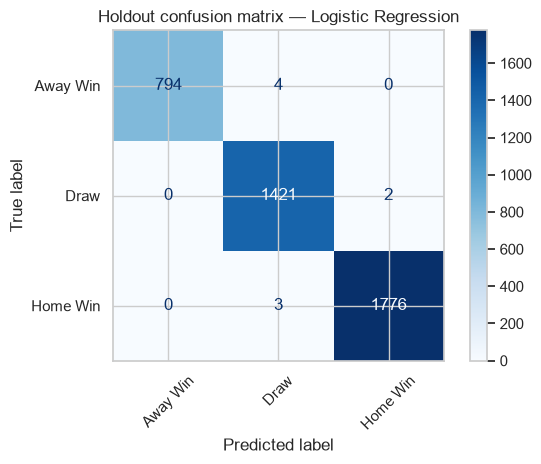

In [21]:
selected_name = cv_results.iloc[0]["model"]
selected_model = fitted_models[selected_name]
selected_pred = selected_model.predict(X_test)

print("Selected using training-only cross-validation:", selected_name)
print("Holdout accuracy:", f"{accuracy_score(y_test, selected_pred):.2%}")
print("\nClassification report:")
print(classification_report(y_test, selected_pred, zero_division=0))

ConfusionMatrixDisplay.from_predictions(
    y_test, selected_pred, xticks_rotation=45, cmap="Blues"
)
plt.title(f"Holdout confusion matrix — {selected_name}")
plt.tight_layout()
plt.show()

## 13. Feature importance (tree-based models)

,model,feature,importance
1,Decision Tree,away_attack,0.233838
0,Decision Tree,home_attack,0.231226
3,Decision Tree,away_defence,0.212718
2,Decision Tree,home_defence,0.184469
4,Decision Tree,home_form,0.076964
5,Decision Tree,away_form,0.056154
6,Decision Tree,home_advantage,0.004631
7,Random Forest,home_attack,0.212390
10,Random Forest,away_defence,0.198975
8,Random Forest,away_attack,0.187175


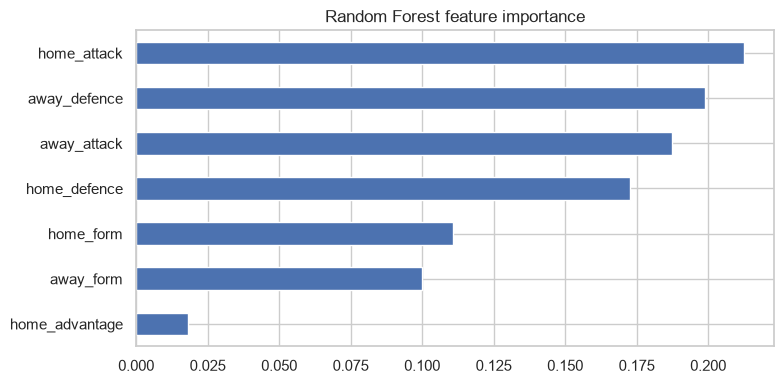

In [22]:
tree_candidates = [name for name in ["Decision Tree", "Random Forest"] if name in fitted_models]
importance_rows = []
for name in tree_candidates:
    model = fitted_models[name]
    if hasattr(model, "feature_importances_"):
        importances = model.feature_importances_
    elif hasattr(model, "named_steps") and hasattr(model.named_steps.get("decisiontreeclassifier", object()), "feature_importances_"):
        importances = model.named_steps["decisiontreeclassifier"].feature_importances_
    else:
        continue
    importance_rows.extend([{"model": name, "feature": f, "importance": float(v)} for f, v in zip(FEATURES, importances)])

importance_df = pd.DataFrame(importance_rows)
if not importance_df.empty:
    display(importance_df.sort_values(["model", "importance"], ascending=[True, False]))
    rf = fitted_models["Random Forest"]
    imp = pd.Series(rf.feature_importances_, index=FEATURES).sort_values()
    imp.plot(kind="barh", figsize=(8, 4), title="Random Forest feature importance")
    plt.tight_layout()
    plt.show()
else:
    print("No feature_importances_ available for the current model types.")

## 14. Cluster hypothetical team profiles

In [23]:
team_profiles = pd.DataFrame({
    "attack": rng.normal(70, 12, 500).clip(20, 100),
    "defence": rng.normal(70, 12, 500).clip(20, 100),
    "possession": rng.normal(52, 10, 500).clip(20, 80),
    "pressing": rng.normal(55, 15, 500).clip(10, 100),
})
cluster_features = team_profiles[["attack", "defence", "possession", "pressing"]]
cluster_scaler = StandardScaler()
cluster_scaled = cluster_scaler.fit_transform(cluster_features)

cluster_scores = []
for k in range(2, 8):
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE)
    labels = km.fit_predict(cluster_scaled)
    cluster_scores.append({"k": k, "silhouette": silhouette_score(cluster_scaled, labels)})

cluster_score_df = pd.DataFrame(cluster_scores)
display(cluster_score_df)
best_k = int(cluster_score_df.sort_values("silhouette", ascending=False).iloc[0]["k"])
team_kmeans = KMeans(n_clusters=best_k, n_init=10, random_state=RANDOM_STATE)
team_profiles["cluster"] = team_kmeans.fit_predict(cluster_scaled)
print("Selected k:", best_k)
display(team_profiles.groupby("cluster").mean(numeric_only=True).round(1))

,k,silhouette
0,2,0.170421
1,3,0.178073
2,4,0.178705
3,5,0.180685
4,6,0.172613
5,7,0.184954


Selected k: 7


,attack,defence,possession,pressing
cluster,,,,
0,81.6,80.1,55.3,50.8
1,74.6,70.1,43.2,71.4
2,66.0,75.1,42.6,40.1
3,56.7,80.2,56.4,53.4
4,71.3,63.7,65.2,64.7
5,81.9,59.4,52.6,42.1
6,61.4,57.4,49.6,58.2


## 15. Predict a hypothetical match scenario

In [24]:
# Example input values. Edit these to explore hypothetical scenarios.
example = pd.DataFrame([{
    "home_attack": 82,
    "away_attack": 75,
    "home_defence": 78,
    "away_defence": 70,
    "home_form": 1.1,
    "away_form": 0.2,
    "home_advantage": 1,
}])
display(example)
print("Predicted class:", selected_model.predict(example)[0])
if hasattr(selected_model, "predict_proba"):
    probabilities = pd.Series(
        selected_model.predict_proba(example)[0],
        index=selected_model.classes_,
        name="probability"
    ).sort_values(ascending=False)
    display(probabilities.to_frame().style.format("{:.2%}"))

,home_attack,away_attack,home_defence,away_defence,home_form,away_form,home_advantage
0,82,75,78,70,1.1,0.2,1


Predicted class: Home Win


,probability
Home Win,100.00%
Draw,0.00%
Away Win,0.00%


## 16. Save the model and results

In [25]:
import joblib
joblib.dump(selected_model, "synthetic_match_classifier.joblib")
model_results.to_csv("synthetic_model_comparison.csv", index=False)
cv_results.to_csv("synthetic_cross_validation.csv", index=False)
print("Saved:")
print("- synthetic_match_classifier.joblib")
print("- synthetic_model_comparison.csv")
print("- synthetic_cross_validation.csv")

Saved:
- synthetic_match_classifier.joblib
- synthetic_model_comparison.csv
- synthetic_cross_validation.csv


## 17. GenAI-powered FIFA analytics assistant

The assistant uses Gemini to answer natural-language questions from concise dataset summaries, the EDA snapshot, and model evaluation results. It does not have live data access. The API key is requested securely and is never hardcoded.

In [26]:
def dataframe_context(df, question, limit=150):
    """Build compact, question-aware context without sending the full CSV."""
    if not isinstance(df, pd.DataFrame) or df.empty:
        return {"rows": 0, "columns": [], "records": [], "note": "No data available."}

    context = {
        "rows": int(len(df)),
        "columns": {str(col): str(dtype) for col, dtype in df.dtypes.items()},
        "numeric_summary": {},
        "categorical_summary": {},
        "records": [],
    }
    numeric = df.select_dtypes(include=np.number)
    if not numeric.empty:
        context["numeric_summary"] = json.loads(numeric.describe().round(3).to_json())

    for col in df.select_dtypes(include=["object", "category", "string"]).columns:
        counts = df[col].value_counts(dropna=True).head(8)
        if not counts.empty:
            context["categorical_summary"][str(col)] = {str(k): int(v) for k, v in counts.items()}

    q = question.lower()
    ranking_requested = any(term in q for term in ["top", "most", "highest", "best", "leader", "rank", "fewest", "least", "lowest"])
    ascending = any(term in q for term in ["fewest", "least", "lowest"])
    metric_terms = [term for term in ["goals", "goal", "assists", "shots", "possession", "minutes", "saves", "age", "cards", "fouls", "points_per_game", "plus_minus"] if term in q]
    ranking_col = None
    if ranking_requested and metric_terms:
        numeric_names = [str(c) for c in df.select_dtypes(include=np.number).columns]
        for term in metric_terms:
            ranking_col = next((c for c in numeric_names if term in c.lower()), None)
            if ranking_col:
                break

    if len(df) <= limit:
        selected = df
    elif ranking_col:
        selected = df.sort_values(ranking_col, ascending=ascending, na_position="last").head(limit)
        context["note"] = f"Rows ranked by {ranking_col}; summaries use the full dataset."
    else:
        selected_indices = set()
        years = re.findall(r"\b(?:19|20)\d{2}\b", q)
        for col in df.columns:
            col_name = str(col).lower()
            if any(term in col_name for term in ["date", "year", "season", "edition"]):
                values = df[col].astype(str)
                for year in years:
                    selected_indices.update(df.index[values.str.contains(year, na=False)].tolist()[:limit])

        tokens = [t for t in re.findall(r"[a-zA-Z0-9]+", q) if len(t) >= 4]
        text_cols = df.select_dtypes(include=["object", "string", "category"]).columns
        if tokens and len(text_cols):
            text = df[text_cols].fillna("").astype(str).agg(" ".join, axis=1).str.lower()
            for token in tokens:
                matches_for_token = df.index[text.str.contains(re.escape(token), na=False)].tolist()
                selected_indices.update(matches_for_token[:min(40, limit)])

        if selected_indices:
            selected = df.loc[df.index.isin(selected_indices)].head(limit)
        else:
            selected = df.head(min(20, limit))
        context["note"] = "Summaries use the full dataset; records are a question-relevant subset or a small sample."

    context["records"] = json.loads(selected.to_json(orient="records", date_format="iso"))
    return context

def build_assistant_context(question):
    dataset_summary = {}
    for name, df in DATASETS.items():
        if isinstance(df, pd.DataFrame) and not df.empty:
            dataset_summary[name] = dataframe_context(df, question)

    ml_summary = {}
    if isinstance(model_results, pd.DataFrame) and not model_results.empty:
        ml_summary["model_comparison"] = json.loads(model_results.to_json(orient="records"))
        ml_summary["synthetic_row_count"] = int(len(synthetic))
        ml_summary["target_class_counts"] = {str(k): int(v) for k, v in synthetic["result"].value_counts().items()}
        ml_summary["limitation"] = "Synthetic-data evaluation does not establish real-world match prediction accuracy."
    if isinstance(cv_results, pd.DataFrame) and not cv_results.empty:
        ml_summary["cross_validation"] = json.loads(cv_results.to_json(orient="records"))

    return {"datasets": dataset_summary, "eda_snapshot": eda_summary, "ml_evaluation": ml_summary}

def ask_football_assistant(question, api_key=None, model_name="gemini-3.5-flash-lite"):
    """Answer a natural-language question using relevant records and verified notebook metrics."""
    key = api_key or os.getenv("GEMINI_API_KEY")
    if not key:
        key = getpass("Enter your Gemini API key (input hidden): ").strip()
    if not key:
        return "No API key provided. Set GEMINI_API_KEY or enter a key when prompted."

    try:
        client = genai.Client(api_key=key)
        context = build_assistant_context(question)
        prompt = f"""
You are the FIFA World Cup Intelligence Assistant.

Answer the user's actual question clearly and directly.
For questions about the supplied datasets, prioritize the provided context and calculate only when the available columns and records support the answer.
Never invent dataset rows, scores, player statistics, or model metrics.
Numeric summaries describe the full dataset, while detailed records may be only a subset; do not treat the subset as the full dataset.
For general football questions, use general knowledge and distinguish it from dataset findings when useful.
If the context does not support a dataset-specific answer, say what is missing.
Do not claim to have live results or real-time data.
State clearly that ML evaluation uses synthetic scenarios and does not establish real-world match prediction accuracy.
Explain possible reasons cautiously; metrics alone do not prove causation.
Use concise tables or bullets when helpful.

NOTEBOOK CONTEXT:
{json.dumps(context, ensure_ascii=False, default=str)}

USER QUESTION:
{question}
"""
        response = client.models.generate_content(model=model_name, contents=prompt)
        if not getattr(response, "text", None):
            return "Gemini returned no text. Please try again."
        return response.text
    except Exception as exc:
        message = str(exc)
        if "429" in message or "RESOURCE_EXHAUSTED" in message:
            issue = "Gemini quota/rate limit reached. Wait and retry, or check quota for your API key and model."
        elif "API key" in message or "API_KEY_INVALID" in message:
            issue = "Gemini rejected the API key. Check that it is valid and enabled."
        elif "403" in message or "PERMISSION_DENIED" in message:
            issue = "Gemini permission/access error. Check API and model access."
        elif "404" in message or "NOT_FOUND" in message:
            issue = "The requested Gemini model was not found or is unavailable."
        else:
            issue = "Gemini request failed. Check network connectivity, model access, and API settings."
        return f"{issue}\nDetails: {type(exc).__name__}: {exc}"

print("Question-aware GenAI assistant is ready. No API request has been made.")
print("Example: ask_football_assistant('Which players scored the most goals?')")

Question-aware GenAI assistant is ready. No API request has been made.
Example: ask_football_assistant('Which players scored the most goals?')


In [ ]:
def dataframe_context(df, question, limit=150):
    """Build question-aware context with full-data summaries and relevant records."""
    if not isinstance(df, pd.DataFrame) or df.empty:
        return {
            "rows": 0,
            "columns": {},
            "records": [],
            "note": "No data available."
        }

    context = {
        "rows": int(len(df)),
        "columns": {str(c): str(t) for c, t in df.dtypes.items()},
        "missing_values": {
            str(c): int(n) for c, n in df.isna().sum().items() if n > 0
        },
        "duplicate_rows": int(df.duplicated().sum()),
        "numeric_summary": {},
        "categorical_summary": {},
        "records": [],
        "note": ""
    }

    numeric = df.select_dtypes(include=np.number)
    if not numeric.empty:
        context["numeric_summary"] = json.loads(
            numeric.describe().round(3).to_json()
        )

    for col in df.select_dtypes(
        include=["object", "category", "string", "bool"]
    ).columns:
        counts = df[col].value_counts(dropna=False).head(12)
        if not counts.empty:
            context["categorical_summary"][str(col)] = {
                str(k): int(v) for k, v in counts.items()
            }

    q = question.lower()
    ranking_requested = any(
        term in q for term in [
            "top", "most", "highest", "best", "leader", "rank",
            "ranking", "fewest", "least", "lowest", "bottom",
            "maximum", "minimum", "youngest", "oldest"
        ]
    )
    ascending = any(
        term in q for term in [
            "fewest", "least", "lowest", "bottom", "minimum",
            "youngest", "oldest"
        ]
    )

    metric_aliases = {
        "goals": ["goals", "goal", "scored", "scoring"],
        "assists": ["assists", "assist"],
        "shots": ["shots", "shot"],
        "possession": ["possession"],
        "minutes": ["minutes", "playing time"],
        "saves": ["saves", "save"],
        "age": ["age", "youngest", "oldest"],
        "cards": ["cards", "yellow cards", "red cards"],
        "fouls": ["fouls", "foul"],
        "points_per_game": ["points_per_game", "points per game"],
        "plus_minus": ["plus_minus", "plus minus"],
        "goals_against": ["goals against", "goals_against", "conceded"],
        "attendance": ["attendance", "spectators"],
        "goal_difference": ["goal difference", "goal_difference"]
    }

    numeric_names = [
        str(c) for c in df.select_dtypes(include=np.number).columns
    ]
    ranking_col = None

    if ranking_requested:
        for metric, aliases in metric_aliases.items():
            if any(alias in q for alias in aliases):
                ranking_col = next(
                    (
                        c for c in numeric_names
                        if metric in c.lower()
                        or metric.replace("_", " ") in c.lower()
                    ),
                    None
                )
                if ranking_col:
                    break

    if len(df) <= limit:
        selected = df.copy()
        context["note"] = "All rows included."

    elif ranking_col:
        selected = df.sort_values(
            ranking_col, ascending=ascending, na_position="last"
        ).head(limit)
        context["note"] = (
            f"Records ranked by {ranking_col}. "
            "Numeric and categorical summaries describe the full dataset."
        )

    else:
        selected_indices = set()
        years = re.findall(r"\b(?:19|20)\d{2}\b", q)

        # Find records matching years in date/year-related columns.
        for col in df.columns:
            if any(
                term in str(col).lower()
                for term in ["date", "year", "season", "edition"]
            ):
                values = df[col].astype(str)
                for year in years:
                    selected_indices.update(
                        df.index[
                            values.str.contains(re.escape(year), na=False)
                        ].tolist()
                    )

        # Search text fields for team, player, venue, round, etc.
        tokens = [
            t for t in re.findall(r"[a-zA-Z0-9]+", q)
            if len(t) >= 3
        ]
        text_cols = df.select_dtypes(
            include=["object", "string", "category"]
        ).columns

        if tokens and len(text_cols):
            text = (
                df[text_cols].fillna("").astype(str)
                .agg(" ".join, axis=1).str.lower()
            )

            for token in tokens:
                matched = df.index[
                    text.str.contains(re.escape(token), na=False)
                ].tolist()
                selected_indices.update(matched[:limit])

        if selected_indices:
            selected = df.loc[
                df.index.isin(selected_indices)
            ].head(limit)
            context["note"] = (
                "Relevant records selected using question terms. "
                "Summaries describe the full dataset."
            )
        else:
            selected = df.head(min(30, limit))
            context["note"] = (
                "Sample records shown because no specific records "
                "could be matched. Summaries describe the full dataset."
            )

    context["records"] = json.loads(
        selected.to_json(orient="records", date_format="iso")
    )
    return context


def build_assistant_context(question):
    #Combine available datasets, EDA results, and ML results safely.
    dataset_summary = {}

    # Use the notebook's existing DATASETS dictionary.
    available_datasets = globals().get("DATASETS", {})

    if isinstance(available_datasets, dict):
        for name, df in available_datasets.items():
            if isinstance(df, pd.DataFrame) and not df.empty:
                dataset_summary[name] = dataframe_context(df, question)

    # Include EDA working dataframes if they exist.
    for name in ["match_eda", "team_eda", "player_eda"]:
        df = globals().get(name)
        if (
            isinstance(df, pd.DataFrame)
            and not df.empty
            and name not in dataset_summary
        ):
            dataset_summary[name] = dataframe_context(df, question)

    ml_summary = {}

    # Collect model evaluation and clustering results when available.
    result_names = [
        "model_results",
        "cv_results",
        "importance_df",
        "cluster_score_df",
        "team_profiles"
    ]

    for name in result_names:
        value = globals().get(name)

        if isinstance(value, pd.DataFrame) and not value.empty:
            ml_summary[name] = {
                "rows": int(len(value)),
                "columns": list(value.columns),
                "results": json.loads(
                    value.head(50).to_json(
                        orient="records", date_format="iso"
                    )
                )
            }

    synthetic = globals().get("synthetic")
    if isinstance(synthetic, pd.DataFrame):
        ml_summary["synthetic_row_count"] = int(len(synthetic))

        if "result" in synthetic.columns:
            ml_summary["target_class_counts"] = {
                str(k): int(v)
                for k, v in synthetic["result"].value_counts().items()
            }

        ml_summary["limitation"] = (
            "The synthetic dataset is artificially generated. "
            "Its evaluation scores do not establish real-world "
            "match prediction accuracy."
        )

    selected_name = globals().get("selected_name")
    if selected_name is not None:
        ml_summary["selected_model"] = str(selected_name)

    selected_model = globals().get("selected_model")
    if selected_model is not None:
        ml_summary["model_classes"] = [
            str(c) for c in getattr(selected_model, "classes_", [])
        ]

    # Include the EDA snapshot only if the notebook created it.
    eda_snapshot = globals().get("eda_summary", {})

    if isinstance(eda_snapshot, pd.DataFrame):
        eda_snapshot = json.loads(
            eda_snapshot.head(50).to_json(orient="records")
        )

    return {
        "datasets": dataset_summary,
        "eda_snapshot": eda_snapshot,
        "ml_evaluation": ml_summary,
        "available_notebook_objects": sorted([
            name for name in [
                "teams", "players", "matches", "match_eda",
                "team_eda", "player_eda", "model_results",
                "cv_results", "selected_model", "team_profiles"
            ] if name in globals()
        ])
    }


def ask_football_assistant(
    question,
    api_key=None,
    model_name="gemini-3.5-flash-lite"
):
    """Answer dataset, EDA, ML and general football questions."""

    question = str(question).strip()
    if not question:
        return "Please enter a question."

    # Keep the key here locally; never share it in chat or publish it.
    key = "api_key"

    if not key or key == "PASTE_YOUR_NEW_GEMINI_API_KEY_HERE":
        return (
            "Set your new Gemini API key in the key line inside this "
            "function before starting the interactive session."
        )

    try:
        client = genai.Client(api_key=key)
        context = build_assistant_context(question)

        # Include recent conversation turns for follow-up questions.
        history = globals().get("football_chat_history", [])
        recent_history = history[-12:] if isinstance(history, list) else []

        history_text = "\n".join(
            f"{item.get('role', 'user').upper()}: "
            f"{item.get('content', '')}"
            for item in recent_history
            if isinstance(item, dict)
        )

        prompt = f"""
You are the FIFA World Cup Intelligence Assistant for a Jupyter
analytics project.

YOUR RESPONSIBILITIES
- Answer questions about the available teams, players and matches.
- Compare teams, players, results, scores and statistical measures.
- Explain EDA, data quality, missing values, distributions, trends
  and correlations using the available notebook evidence.
- Explain model comparison, cross-validation, classification reports,
  confusion matrices, feature importance and clustering.
- Explain hypothetical model predictions and their limitations.
- Answer general football questions, clearly distinguishing general
  knowledge from findings in the supplied datasets.
- Understand follow-up questions using the conversation history.

ACCURACY RULES
1. Answer the specific question directly.
2. Use the notebook context for dataset-specific answers.
3. Full-dataset summaries describe all available rows. The records
   supplied may be only a subset; do not confuse them.
4. Never invent data, columns, match results, metrics or citations.
5. If the exact answer cannot be established from the supplied
   context, state the limitation rather than guessing.
6. If a calculation is supported by the provided values, explain
   the calculation and units.
7. Do not claim live scores, current standings or real-time access.
8. Synthetic ML results are not evidence of real-world prediction
   accuracy. Clearly state this when relevant.
9. Correlation does not prove causation.
10. For general football questions, distinguish general knowledge
    from this project's dataset findings.
11. Use tables or bullet points when useful, but avoid unnecessary
    repetition.
12. For follow-up questions, interpret references using the history.
13. Never reveal API keys or other secrets.

RECENT CONVERSATION:
{history_text if history_text else "No earlier questions in this session."}

NOTEBOOK CONTEXT:
{json.dumps(context, ensure_ascii=False, default=str)}

USER QUESTION:
{question}
"""

        response = client.models.generate_content(
            model=model_name,
            contents=prompt
        )

        answer = getattr(response, "text", None)

        if not answer:
            return "Gemini returned no text. Please rephrase the question."

        # Maintain a bounded history for conversational follow-ups.
        if "football_chat_history" not in globals():
            globals()["football_chat_history"] = []

        football_chat_history.append(
            {"role": "user", "content": question}
        )
        football_chat_history.append(
            {"role": "assistant", "content": answer}
        )

        del football_chat_history[:-12]

        return answer

    except Exception as exc:
        message = str(exc)
        upper = message.upper()

        if "429" in message or "RESOURCE_EXHAUSTED" in upper:
            issue = (
                "Gemini quota or rate limit reached. Check your "
                "API quota and try again when available."
            )
        elif "API_KEY_INVALID" in upper or "INVALID API KEY" in upper:
            issue = "Gemini rejected the API key. Check that it is valid."
        elif "403" in message or "PERMISSION_DENIED" in upper:
            issue = (
                "Gemini access denied. Check API permissions and "
                "model availability."
            )
        elif "404" in message or "NOT_FOUND" in upper:
            issue = (
                f"The model '{model_name}' may be unavailable. "
                "Check the model name and supported models."
            )
        elif "TIMEOUT" in upper or "CONNECTION" in upper:
            issue = (
                "Connection problem. Check your network and retry."
            )
        else:
            issue = (
                "Gemini request failed. Check the API configuration "
                "and connection."
            )

        return f"{issue}\nDetails: {type(exc).__name__}: {exc}"


# ---------------- INTERACTIVE FIFA Q&A SESSION ------------------

print("=" * 60)
print("  FIFA WORLD CUP INTELLIGENCE ASSISTANT")
print("=" * 60)
print("Ask about teams, players, matches, EDA, ML or football.")
print("Follow-up questions are supported.")
print("Type 'help' for examples, 'clear' to reset history,")
print("or 'exit' to end the session.")
print("-" * 60)

while True:
    try:
        question = input("\nYou: ").strip()

        if question.lower() in {"exit", "quit", "bye"}:
            print("\nAssistant: Thanks for using FIFA World Cup Intelligence!")
            break

        if not question:
            continue

        if question.lower() == "clear":
            football_chat_history = []
            print("\nAssistant: Conversation history cleared.")
            continue

        if question.lower() == "help":
            print("""
Examples:
- Which team scored the most goals?
- Compare the top players by goals and assists.
- Summarise the match outcomes in my dataset.
- What are the main EDA findings?
- Which columns have missing values?
- Explain the selected model's performance.
- What does the confusion matrix mean?
- Explain the clustering results.
- Explain that finding in simpler terms.
- What are the limitations of this analysis?
""")
            continue

        print("\nAssistant: Thinking...\n")
        print(ask_football_assistant(question))
        print("\n" + "-" * 60)

    except KeyboardInterrupt:
        print("\n\nAssistant: Session ended. Goodbye!")
        break

    except EOFError:
        print("\nAssistant: Session ended. Goodbye!")
        break

  FIFA WORLD CUP INTELLIGENCE ASSISTANT
Ask about teams, players, matches, EDA, ML or football.
Follow-up questions are supported.
Type 'help' for examples, 'clear' to reset history,
or 'exit' to end the session.
------------------------------------------------------------



You:  top 3 players, their goals, country, team name?



Assistant: Thinking...

Gemini quota or rate limit reached. Check your API quota and try again when available.
Details: ClientError: 429 RESOURCE_EXHAUSTED. {'error': {'code': 429, 'message': 'You exceeded your current quota, please check your plan and billing details. For more information on this error, head to: https://ai.google.dev/gemini-api/docs/rate-limits. To monitor your current usage, head to: https://ai.dev/rate-limit. \n* Quota exceeded for metric: generativelanguage.googleapis.com/generate_content_free_tier_input_token_count, limit: 250000, model: gemini-3.5-flash-lite, description: Generate content input tokens per minute limit exceeded on Free Tier. See https://ai.google.dev/gemini-api/docs/rate-limits.\nPlease retry in 51.021365371s.', 'status': 'RESOURCE_EXHAUSTED', 'details': [{'@type': 'type.googleapis.com/google.rpc.Help', 'links': [{'description': 'Learn more about Gemini API quotas', 'url': 'https://ai.google.dev/gemini-api/docs/rate-limits'}]}, {'@type': 'type.go


You:  top 3 players, their goals, country, team name?



Assistant: Thinking...

Gemini quota or rate limit reached. Check your API quota and try again when available.
Details: ClientError: 429 RESOURCE_EXHAUSTED. {'error': {'code': 429, 'message': 'You exceeded your current quota, please check your plan and billing details. For more information on this error, head to: https://ai.google.dev/gemini-api/docs/rate-limits. To monitor your current usage, head to: https://ai.dev/rate-limit. \n* Quota exceeded for metric: generativelanguage.googleapis.com/generate_content_free_tier_input_token_count, limit: 250000, model: gemini-3.5-flash-lite, description: Generate content input tokens per minute limit exceeded on Free Tier. See https://ai.google.dev/gemini-api/docs/rate-limits.\nPlease retry in 41.970154991s.', 'status': 'RESOURCE_EXHAUSTED', 'details': [{'@type': 'type.googleapis.com/google.rpc.Help', 'links': [{'description': 'Learn more about Gemini API quotas', 'url': 'https://ai.google.dev/gemini-api/docs/rate-limits'}]}, {'@type': 'type.go

...


Assistant: Thinking...

Gemini quota or rate limit reached. Check your API quota and try again when available.
Details: ClientError: 429 RESOURCE_EXHAUSTED. {'error': {'code': 429, 'message': 'You exceeded your current quota, please check your plan and billing details. For more information on this error, head to: https://ai.google.dev/gemini-api/docs/rate-limits. To monitor your current usage, head to: https://ai.dev/rate-limit. \n* Quota exceeded for metric: generativelanguage.googleapis.com/generate_content_free_tier_input_token_count, limit: 250000, model: gemini-3.5-flash-lite, description: Generate content input tokens per minute limit exceeded on Free Tier. See https://ai.google.dev/gemini-api/docs/rate-limits.\nPlease retry in 39.794639564s.', 'status': 'RESOURCE_EXHAUSTED', 'details': [{'@type': 'type.googleapis.com/google.rpc.Help', 'links': [{'description': 'Learn more about Gemini API quotas', 'url': 'https://ai.google.dev/gemini-api/docs/rate-limits'}]}, {'@type': 'type.go


You:  top 3 players, their goals, country, team name?



Assistant: Thinking...

Gemini quota or rate limit reached. Check your API quota and try again when available.
Details: ClientError: 429 RESOURCE_EXHAUSTED. {'error': {'code': 429, 'message': 'You exceeded your current quota, please check your plan and billing details. For more information on this error, head to: https://ai.google.dev/gemini-api/docs/rate-limits. To monitor your current usage, head to: https://ai.dev/rate-limit. \n* Quota exceeded for metric: generativelanguage.googleapis.com/generate_content_free_tier_input_token_count, limit: 250000, model: gemini-3.5-flash-lite, description: Generate content input tokens per minute limit exceeded on Free Tier. See https://ai.google.dev/gemini-api/docs/rate-limits.\nPlease retry in 33.434270969s.', 'status': 'RESOURCE_EXHAUSTED', 'details': [{'@type': 'type.googleapis.com/google.rpc.Help', 'links': [{'description': 'Learn more about Gemini API quotas', 'url': 'https://ai.google.dev/gemini-api/docs/rate-limits'}]}, {'@type': 'type.go


You:  exit



Assistant: Thanks for using FIFA World Cup Intelligence!


### 17.1 Optional GenAI demo

Set `RUN_GENAI_DEMO = True` only when you want to make a Gemini API request. The key is requested securely if it is not in your environment.

In [35]:
RUN_GENAI_DEMO = True  # Change to True when you are ready to call Gemini.
if RUN_GENAI_DEMO:
    print(ask_football_assistant("Summarize three findings supported by this notebook and explain the limitations."))
else:
    print("GenAI demo is off. Set RUN_GENAI_DEMO = True to run it.")

Gemini quota or rate limit reached. Check your API quota and try again when available.
Details: ClientError: 429 RESOURCE_EXHAUSTED. {'error': {'code': 429, 'message': 'You exceeded your current quota, please check your plan and billing details. For more information on this error, head to: https://ai.google.dev/gemini-api/docs/rate-limits. To monitor your current usage, head to: https://ai.dev/rate-limit. \n* Quota exceeded for metric: generativelanguage.googleapis.com/generate_content_free_tier_input_token_count, limit: 250000, model: gemini-3.5-flash-lite, description: Generate content input tokens per minute limit exceeded on Free Tier. See https://ai.google.dev/gemini-api/docs/rate-limits.\nPlease retry in 22.276949264s.', 'status': 'RESOURCE_EXHAUSTED', 'details': [{'@type': 'type.googleapis.com/google.rpc.Help', 'links': [{'description': 'Learn more about Gemini API quotas', 'url': 'https://ai.google.dev/gemini-api/docs/rate-limits'}]}, {'@type': 'type.googleapis.com/google.rpc.Q

## 18. Conclusions and portfolio checklist

Use the actual outputs above to write a concise, evidence-based conclusion:

- **EDA findings:** summarize one match-level, one team-level, and one player-level finding supported by the plots.
- **Holdout performance:** see `model_results` and the classification report.
- **Most useful features:** inspect feature importance and confirm the simulation rule.
- **Cluster interpretation:** describe the average profile of each cluster.
- **Limitations:** synthetic labels are rule-generated; real tournament performance is not validated by these scores.
- **Next step:** add verified historical results and pre-match features, then validate on later seasons or tournaments.

### Troubleshooting
- If CSV files aren't found, copy `teams.csv`, `players.csv`, and `matches.csv` beside this notebook or into a `data/` subfolder.
- If a package install completes but imports fail, restart the notebook kernel and run the cells again.
- If Gemini imports fail, rerun the dependency-install cell, restart the kernel, and run the notebook again. For API errors, check `GEMINI_API_KEY`, model access, and quota. Never paste your API key into a notebook cell or publish it.